# Day 3 — Dataset Preparation, Preprocessing, and Baseline Model

**Objective:** Build a reproducible supervised-learning workflow for predicting customer churn.

This notebook loads the source CSV independently, applies the documented `TotalCharges` cleaning assumption, separates features and target, creates training/validation/test partitions, and builds a Logistic Regression baseline.

**Evaluation note:** An earlier version of this notebook used the original test partition for an exploratory threshold experiment. Because that partition was used during model development, it must not be described as an untouched final test set. Day 4 uses validation data for comparisons; no final test score is claimed here.

## 1. Imports and Load Data

This notebook must run independently; it does not depend on variables created in `01_data_inspection.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

df = pd.read_csv("../data/telco-customer-churn.csv")
print("Dataset shape before cleaning:", df.shape)

Dataset shape before cleaning: (7043, 21)


## 2. Apply the Documented Cleaning Step

In the inspection notebook, 11 `TotalCharges` entries were found to contain whitespace rather than ordinary null values. These were associated with zero-tenure customers. We provisionally replace blank values with zero, as documented in the EDA notebook; validate this assumption against the dataset definition before production use.

In [2]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip().replace("", pd.NA),
    errors="raise"
)
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after cleaning:", df.isnull().sum().sum())
print("TotalCharges dtype:", df["TotalCharges"].dtype)
print("Dataset shape after cleaning:", df.shape)

Missing values after cleaning: 0
TotalCharges dtype: float64
Dataset shape after cleaning: (7043, 21)


## 3. Define Features (`X`) and Target (`y`)

`Churn` is the outcome we want to predict, so it must not appear among the input features. `customerID` is an identifier and is excluded from the initial model inputs.

In [3]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution (%):")
print(y.value_counts(normalize=True).mul(100).round(2))

X shape: (7043, 19)
y shape: (7043,)

Target distribution (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## 4. Create Training, Validation, and Test Sets

We first reserve 20% of the records as a test partition, then split the remaining 80% into training and validation subsets. The resulting proportions are approximately 60% training, 20% validation, and 20% test.

**Important limitation:** This notebook originally explored a threshold using a test split created with `random_state=42`. The split below retains that seed for reproducibility, so the test partition is not new or untouched. Do not use it to choose models or thresholds, and do not present it as an independent final evaluation.

### Split Procedure

- **Training set (60%):** used to fit the model and preprocessing steps.
- **Validation set (20%):** used to compare model configurations and select a threshold.
- **Test partition (20%):** retained for reference only in this notebook; it is not treated as an untouched final test set because it was used in an earlier exploratory experiment.

Stratified splitting preserves the churn/non-churn proportions approximately in each subset.

In [4]:
# Reserve 20% as the test partition; note that this partition was used in an earlier exploratory experiment.
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining 80% into training and validation sets.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nChurn proportion in each set:")
print("Training:", y_train.value_counts(normalize=True))
print("Validation:", y_val.value_counts(normalize=True))
print("Test:", y_test.value_counts(normalize=True))

Training set: (4225, 19) (4225,)
Validation set: (1409, 19) (1409,)
Test set: (1409, 19) (1409,)

Churn proportion in each set:
Training: Churn
No     0.734675
Yes    0.265325
Name: proportion, dtype: float64
Validation: Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64
Test: Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


## 5. Identify Feature Groups

We use data types to identify the initial groups, then explicitly treat `SeniorCitizen` as a categorical indicator. It is stored as 0/1, but those values represent categories rather than a continuous measurement. Treating it as numeric could also be defensible; this notebook makes the chosen treatment explicit.

In [5]:
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numerical_features.remove("SeniorCitizen")
categorical_features.append("SeniorCitizen")

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']
Number of numerical features: 3
Number of categorical features: 16


## 6. Build the Preprocessor

`StandardScaler` learns each numerical feature's mean and standard deviation from training data. `OneHotEncoder` converts categorical values into indicator columns. `handle_unknown="ignore"` prevents an unseen category from causing an error during transformation.

We will fit this preprocessor through the pipeline, using training data only.

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

## 7. Build and Train the Baseline Pipeline

The pipeline combines preprocessing and Logistic Regression. Passing the original `X_train` to `.fit()` lets the pipeline fit the transformations on training data and then train the classifier on the transformed features.

In [7]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

## Day 4 — Model Evaluation and Error Analysis

### 1. Generate Validation Predictions

Use the fitted pipeline to predict churn labels for the validation set. These predictions will help us evaluate the model and compare classification thresholds without repeatedly consulting the test set.

In [8]:
y_val_pred = model.predict(X_val)

In [9]:
print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred, pos_label="Yes"))
print("Recall:", recall_score(y_val, y_val_pred, pos_label="Yes"))
print("F1-score:", f1_score(y_val, y_val_pred, pos_label="Yes"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred, labels=["No", "Yes"]))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Accuracy: 0.8026969481902059
Precision: 0.6578947368421053
Recall: 0.5347593582887701
F1-score: 0.5899705014749262

Confusion Matrix:
[[931 104]
 [174 200]]

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



### 2.1 Validation Baseline — Interpretation

The baseline Logistic Regression model was evaluated on the validation set using the default classification threshold of 0.50.

- **Accuracy:** 80.27%
- **Precision (churn):** 65.79%
- **Recall (churn):** 53.48%
- **F1-score (churn):** 59.00%

The confusion matrix contains 931 true negatives, 104 false positives, 174 false negatives, and 200 true positives.

The model correctly identifies many customers who stay, but it misses 174 of the 374 customers who actually churned in the validation set. Improving churn detection while controlling false positives is therefore a key objective for subsequent experiments.

These validation results establish the baseline for comparing classification thresholds and model configurations.

### 2.2 Generate Validation Probabilities

Logistic Regression can estimate a probability for each class. We use the predicted probability of churn to evaluate alternative classification thresholds on the validation set.

In [10]:
y_val_prob = model.predict_proba(X_val)[:, 1]

### 2.3 Compare Classification Thresholds

Logistic Regression produces predicted probabilities, which are converted into class labels using a decision threshold.

A customer is predicted to churn when their predicted churn probability is greater than or equal to the threshold.

Lower thresholds generally increase recall while reducing precision. We will compare several thresholds using validation data and select an operating point based on the business objective.

In [11]:
thresholds = [0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    y_val_pred_threshold = np.where(
        y_val_prob >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred_threshold, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_val, y_val_pred_threshold, pos_label="Yes"
        ),
        "F1-score": f1_score(
            y_val, y_val_pred_threshold, pos_label="Yes"
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)
threshold_results_df

,Threshold,Precision,Recall,F1-score
0,0.3,0.538314,0.751337,0.627232
1,0.4,0.595062,0.644385,0.618742
2,0.5,0.657895,0.534759,0.589971


### 2.4 Threshold Comparison — Findings

Three classification thresholds were evaluated using validation probabilities.

- **Threshold 0.30:** Precision = 53.83%, Recall = 75.13%, F1-score = 62.72%.
- **Threshold 0.40:** Precision = 59.51%, Recall = 64.44%, F1-score = 61.87%.
- **Threshold 0.50:** Precision = 65.79%, Recall = 53.48%, F1-score = 59.00%.

Lowering the threshold increased recall while reducing precision. Among the tested thresholds, 0.30 achieved the highest recall and F1-score, while 0.50 achieved the highest precision.

Threshold 0.30 is a candidate for further investigation, not yet a final deployment decision. The appropriate threshold depends on retention-campaign costs, campaign effectiveness, and the relative costs of false positives and false negatives.

### 2.5 Confusion Matrix Comparison

A confusion matrix shows the counts of true negatives, false positives, false negatives, and true positives for a classification threshold.

Comparing confusion matrices across thresholds helps quantify the operational trade-off between identifying more customers who churn and flagging customers who would stay.

In [12]:
for threshold in [0.30, 0.40, 0.50]:
    y_val_pred_threshold = np.where(
        y_val_prob >= threshold,
        "Yes",
        "No"
    )

    cm = confusion_matrix(
        y_val,
        y_val_pred_threshold,
        labels=["No", "Yes"]
    )

    print(f"\nThreshold: {threshold:.2f}")
    print(cm)


Threshold: 0.30
[[794 241]
 [ 93 281]]

Threshold: 0.40
[[871 164]
 [133 241]]

Threshold: 0.50
[[931 104]
 [174 200]]


### 2.6 Confusion Matrix Comparison — Findings

The confusion matrices show how the classification threshold affects the number of customers flagged for potential churn.

- At threshold 0.30, the model identifies 281 churners, misses 93, and produces 241 false positives.
- At threshold 0.40, the model identifies 241 churners, misses 133, and produces 164 false positives.
- At threshold 0.50, the model identifies 200 churners, misses 174, and produces 104 false positives.

Lowering the threshold from 0.50 to 0.30 identifies 81 additional churners and reduces missed churners by 81, while increasing false positives by 137. The number of customers flagged rises from 304 to 522.

The best operating threshold depends on retention-campaign costs and benefits. These validation results support further investigation but do not establish campaign profitability.

### 2.7 Ranking Metrics: ROC-AUC and Average Precision

ROC-AUC measures the model's ability to rank customers who churn above customers who stay across different classification thresholds.

Average Precision summarizes the precision-recall relationship across thresholds. It is particularly useful when the positive class is less common than the negative class.

Both metrics use predicted probabilities rather than class labels. They evaluate ranking performance and do not, by themselves, determine the best deployment threshold.

In [13]:
roc_auc = roc_auc_score(
    (y_val == "Yes").astype(int),
    y_val_prob
)

average_precision = average_precision_score(
    (y_val == "Yes").astype(int),
    y_val_prob
)

print(f"Validation ROC-AUC: {roc_auc:.4f}")
print(f"Validation Average Precision: {average_precision:.4f}")

Validation ROC-AUC: 0.8360
Validation Average Precision: 0.6424


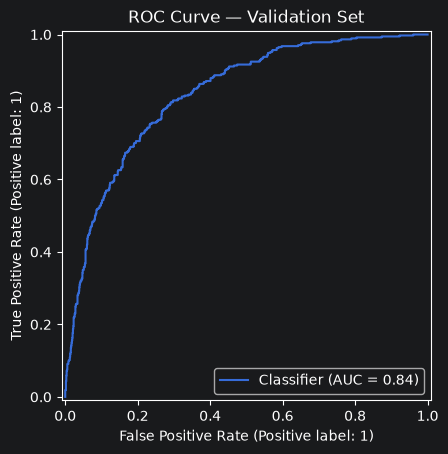

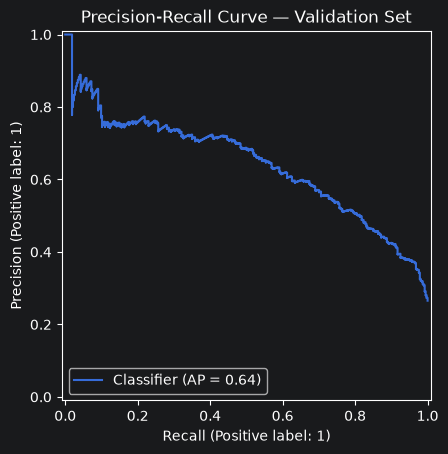

In [14]:
RocCurveDisplay.from_predictions(
    (y_val == "Yes").astype(int),
    y_val_prob
)
plt.title("ROC Curve — Validation Set")
plt.show()

PrecisionRecallDisplay.from_predictions(
    (y_val == "Yes").astype(int),
    y_val_prob
)
plt.title("Precision-Recall Curve — Validation Set")
plt.show()

### 2.8 Ranking Metrics — Findings

The baseline Logistic Regression model achieved the following validation ranking metrics:

- **ROC-AUC:** 0.8360
- **Average Precision:** 0.6424

The ROC-AUC suggests that the model can distinguish churners from non-churners reasonably well by ranking their predicted probabilities. Average Precision is substantially above the approximate positive-class prevalence of 26.5%, indicating useful precision-recall ranking performance.

These metrics evaluate ranking across thresholds. They do not identify the best deployment threshold, establish probability calibration, or prove that a retention campaign will be profitable.

The next step is to inspect the ROC and Precision-Recall curves and investigate the customers the model misclassifies.

## 2. Error Analysis

Error analysis examines individual predictions to identify patterns in false positives and false negatives.

We will compare the actual churn labels with the model's predicted labels and probabilities on the validation set. This analysis can reveal which types of customers the model struggles to classify and help guide further experiments.

In [15]:
error_analysis = X_val.copy()

error_analysis["Actual_Churn"] = y_val
error_analysis["Predicted_Churn"] = y_val_pred
error_analysis["Churn_Probability"] = y_val_prob

error_analysis["Error_Type"] = np.select(
    [
        (error_analysis["Actual_Churn"] == "Yes") &
        (error_analysis["Predicted_Churn"] == "No"),

        (error_analysis["Actual_Churn"] == "No") &
        (error_analysis["Predicted_Churn"] == "Yes")
    ],
    [
        "False Negative",
        "False Positive"
    ],
    default="Correct"
)

error_analysis.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Error_Type
2103,Male,1,Yes,No,11,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.20,834.70,No,Yes,0.645622,False Positive
6096,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.20,70.20,No,Yes,0.730872,False Positive
4286,Male,0,Yes,No,9,Yes,Yes,Fiber optic,Yes,No,...,Yes,Month-to-month,Yes,Electronic check,88.05,801.30,No,Yes,0.659496,False Positive
815,Female,0,No,No,25,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Mailed check,84.60,2088.05,No,Yes,0.608751,False Positive
4297,Female,0,No,No,45,Yes,Yes,DSL,Yes,No,...,Yes,Two year,No,Mailed check,73.55,3349.10,No,No,0.020093,Correct


In [16]:
error_analysis["Error_Type"].value_counts()

Error_Type
Correct           1131
False Negative     174
False Positive     104
Name: count, dtype: int64

In [17]:
false_negatives = error_analysis[
    error_analysis["Error_Type"] == "False Negative"
]

false_negatives.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Error_Type
4539,Male,0,Yes,Yes,67,Yes,Yes,DSL,Yes,No,...,Yes,Two year,Yes,Electronic check,79.7,5293.40,Yes,No,0.026258,False Negative
6290,Female,0,Yes,No,71,Yes,Yes,Fiber optic,No,No,...,Yes,Two year,Yes,Bank transfer (automatic),93.7,6585.35,Yes,No,0.092229,False Negative
6772,Male,0,No,No,38,Yes,No,DSL,No,No,...,Yes,One year,Yes,Mailed check,62.3,2354.80,Yes,No,0.068803,False Negative
2287,Male,1,Yes,No,69,Yes,Yes,Fiber optic,No,Yes,...,Yes,Two year,Yes,Bank transfer (automatic),108.4,7318.20,Yes,No,0.077076,False Negative
6032,Male,1,Yes,No,68,Yes,Yes,Fiber optic,No,Yes,...,Yes,Month-to-month,Yes,Electronic check,105.3,7299.65,Yes,No,0.451154,False Negative


In [18]:
false_positives = error_analysis[
    error_analysis["Error_Type"] == "False Positive"
]

false_positives.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability,Error_Type
2103,Male,1,Yes,No,11,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.20,834.70,No,Yes,0.645622,False Positive
6096,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.20,70.20,No,Yes,0.730872,False Positive
4286,Male,0,Yes,No,9,Yes,Yes,Fiber optic,Yes,No,...,Yes,Month-to-month,Yes,Electronic check,88.05,801.30,No,Yes,0.659496,False Positive
815,Female,0,No,No,25,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Mailed check,84.60,2088.05,No,Yes,0.608751,False Positive
1929,Male,0,Yes,Yes,1,Yes,No,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,81.05,81.05,No,Yes,0.674054,False Positive


### 2.1 Investigating False Negatives by Contract

Contract type was strongly associated with churn during exploratory data analysis. We will examine the contract types of customers the model failed to identify, then compare these patterns with the full validation set.

This analysis is exploratory: it helps identify potential weaknesses but does not establish why an individual prediction was wrong.

In [19]:
false_negatives["Contract"].value_counts()

Contract
Month-to-month    124
One year           37
Two year           13
Name: count, dtype: int64

In [20]:
contract_errors = error_analysis.groupby("Contract").apply(
    lambda group: (
        (group["Error_Type"] == "False Negative").sum()
        / (group["Actual_Churn"] == "Yes").sum()
    ),
    include_groups=False
)

contract_errors.sort_values(ascending=False)

Contract
One year          1.000000
Two year          1.000000
Month-to-month    0.382716
dtype: float64

In [21]:
contract_error_summary = pd.DataFrame({
    "Actual_Churners": error_analysis[
        error_analysis["Actual_Churn"] == "Yes"
    ].groupby("Contract").size(),

    "False_Negatives": error_analysis[
        error_analysis["Error_Type"] == "False Negative"
    ].groupby("Contract").size(),

    "False_Negative_Rate": contract_errors
})

contract_error_summary

,Actual_Churners,False_Negatives,False_Negative_Rate
Contract,,,
Month-to-month,324,124,0.382716
One year,37,37,1.000000
Two year,13,13,1.000000


In [22]:
contract_churn_rate = (
    error_analysis.groupby("Contract")["Actual_Churn"]
    .apply(lambda values: (values == "Yes").mean())
)

contract_error_summary["Churn_Rate"] = contract_churn_rate

contract_error_summary

,Actual_Churners,False_Negatives,False_Negative_Rate,Churn_Rate
Contract,,,,
Month-to-month,324,124,0.382716,0.417526
One year,37,37,1.000000,0.120130
Two year,13,13,1.000000,0.040000


### 2.2 Inspect Predicted Probabilities of Missed Churners

The model missed all 37 actual churners with one-year contracts and all 13 actual churners with two-year contracts in the validation sample at the default threshold of 0.50.

Because these groups contain relatively few churners, their false-negative rates should be interpreted cautiously. We will inspect the predicted churn probabilities of these customers to determine whether the missed cases are close to the classification threshold or receive very low risk scores.

In [23]:
false_negatives.groupby("Contract")["Churn_Probability"].agg(
    ["count", "min", "mean", "median", "max"]
)

,count,min,mean,median,max
Contract,,,,,
Month-to-month,124,0.015418,0.328673,0.344765,0.497995
One year,37,0.008748,0.154667,0.135882,0.452760
Two year,13,0.003187,0.070994,0.073675,0.243852


### 2.3 Compare Correctly Identified and Missed Churners

We will compare the characteristics of actual churners who were correctly identified by the model with those who were classified as non-churners.

The purpose is to identify potential patterns in prediction errors, including differences in tenure, monthly charges, total charges, and contract type. These comparisons are exploratory and do not establish causation.

In [24]:
actual_churners = error_analysis[
    error_analysis["Actual_Churn"] == "Yes"
].copy()

actual_churners["Detection_Status"] = np.where(
    actual_churners["Predicted_Churn"] == "Yes",
    "Correctly Identified",
    "Missed"
)

actual_churners.groupby("Detection_Status")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].agg(["count", "mean", "median"])

tenure                   MonthlyCharges             \
                      count       mean median          count       mean   
Detection_Status                                                          
Correctly Identified    200  12.495000    8.0            200  82.976000   
Missed                  174  28.568966   23.5            174  67.584483   

                             TotalCharges                        
                      median        count        mean    median  
Detection_Status                                                 
Correctly Identified  84.925          200  1138.42250   661.775  
Missed                65.850          174  2356.23592  1214.050

### 2.4 Error Analysis — Numerical Feature Findings

Comparing correctly identified churners with missed churners revealed the following patterns:

- Correctly identified churners had a mean tenure of 12.50 months and a median tenure of 8 months.
- Missed churners had a mean tenure of 28.57 months and a median tenure of 23.5 months.
- Mean monthly charges were approximately 82.98 for correctly identified churners and 67.58 for missed churners.
- Mean total charges were approximately 1,138.42 for correctly identified churners and 2,356.24 for missed churners.

These descriptive results suggest that the baseline model identifies short-tenure, higher-monthly-charge churners more effectively than some longer-tenure, lower-monthly-charge churners. Further investigation is needed before attributing these errors to specific features or making modeling changes.

### 2.5 Error Analysis — Contract Patterns

We will compare contract types among actual churners who were correctly identified and those who were missed by the baseline model.

This analysis builds on the earlier finding that the model missed all observed validation churners with one-year and two-year contracts at the default threshold. We will compare the groups' distributions while keeping sample sizes in mind.

In [25]:
pd.crosstab(
    actual_churners["Contract"],
    actual_churners["Detection_Status"],
    normalize="index"
).round(3).mul(100)

Detection_Status,Correctly Identified,Missed
Contract,,
Month-to-month,61.7,38.3
One year,0.0,100.0
Two year,0.0,100.0


### 2.6 Contract-Level Error Analysis — Findings

Among actual churners in the validation set, the baseline model correctly identified 61.7% of month-to-month customers and missed 38.3%.

The model missed all observed churners in the one-year and two-year contract groups at the default threshold of 0.50.

The longer-contract groups contain fewer actual churners, so their observed detection rates should be interpreted cautiously. These results suggest that the baseline model may not generalize equally well across contract groups and motivate further controlled experiments.

## 3. Controlled Model Improvement

### 4.1 Experiment: Class-Weighted Logistic Regression

The baseline model may favor the majority class because non-churners outnumber churners. We will test Logistic Regression with `class_weight="balanced"` to increase the relative penalty for misclassifying the minority class.

Only the classifier setting will change. We will keep the training and validation splits, preprocessing approach, and evaluation metrics consistent so that the comparison isolates the effect of class weighting.

In [26]:
from sklearn.base import clone

In [27]:
weighted_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        )
    ]
)

In [28]:
weighted_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

### 3.1 Evaluate the Class-Weighted Model

Evaluate the class-weighted Logistic Regression model on the same validation set used for the baseline. Compare precision, recall, F1-score, and confusion matrix to determine how class weighting affects churn detection.

In [29]:
y_val_pred_weighted = weighted_model.predict(X_val)

In [30]:
print("Weighted Model — Validation Results")
print("Accuracy:", accuracy_score(y_val, y_val_pred_weighted))
print(
    "Precision:",
    precision_score(y_val, y_val_pred_weighted, pos_label="Yes")
)
print(
    "Recall:",
    recall_score(y_val, y_val_pred_weighted, pos_label="Yes")
)
print(
    "F1-score:",
    f1_score(y_val, y_val_pred_weighted, pos_label="Yes")
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_val_pred_weighted,
        labels=["No", "Yes"]
    )
)

Weighted Model — Validation Results
Accuracy: 0.7480482611781405
Precision: 0.5166374781085814
Recall: 0.7887700534759359
F1-score: 0.6243386243386243

Confusion Matrix:
[[759 276]
 [ 79 295]]


In [31]:
model_comparison = pd.DataFrame([
    {
        "Model": "Baseline Logistic Regression",
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(
            y_val, y_val_pred, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_val, y_val_pred, pos_label="Yes"
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, pos_label="Yes"
        )
    },
    {
        "Model": "Class-Weighted Logistic Regression",
        "Accuracy": accuracy_score(y_val, y_val_pred_weighted),
        "Precision": precision_score(
            y_val, y_val_pred_weighted, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_val, y_val_pred_weighted, pos_label="Yes"
        ),
        "F1-score": f1_score(
            y_val, y_val_pred_weighted, pos_label="Yes"
        )
    }
])

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline Logistic Regression,0.8027,0.6579,0.5348,0.5900
1,Class-Weighted Logistic Regression,0.7480,0.5166,0.7888,0.6243


### 3.2 Class-Weighted Logistic Regression — Findings

The class-weighted Logistic Regression model was evaluated on the same validation set as the baseline, using the default threshold of 0.50.

| Metric | Baseline | Class-weighted |
|---|---:|---:|
| Accuracy | 80.27% | 74.80% |
| Precision | 65.79% | 51.66% |
| Recall | 53.48% | 78.88% |
| F1-score | 59.00% | 62.43% |

Class weighting increased recall by 25.40 percentage points and F1-score by approximately 3.43 percentage points, while reducing accuracy and precision.

The weighted model is a promising candidate for a retention strategy that prioritizes identifying more churners. However, the additional false positives must be considered before selecting a model for deployment. This comparison is based on validation performance and is not a final test evaluation.

### 3.3 Threshold Analysis — Class-Weighted Model

The class-weighted model changes how Logistic Regression treats errors on each class. Its predicted probabilities may therefore differ from those of the baseline model.

We will evaluate multiple thresholds on validation data to compare precision, recall, and F1-score. The test set will not be used to select a threshold.

In [32]:
y_val_prob_weighted = weighted_model.predict_proba(X_val)[:, 1]

In [33]:
thresholds = [0.30, 0.40, 0.50]
weighted_threshold_results = []

for threshold in thresholds:
    y_val_pred_weighted_threshold = np.where(
        y_val_prob_weighted >= threshold,
        "Yes",
        "No"
    )

    weighted_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred_weighted_threshold, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_val, y_val_pred_weighted_threshold, pos_label="Yes"
        ),
        "F1-score": f1_score(
            y_val, y_val_pred_weighted_threshold, pos_label="Yes"
        )
    })

weighted_threshold_results_df = pd.DataFrame(
    weighted_threshold_results
)

weighted_threshold_results_df

,Threshold,Precision,Recall,F1-score
0,0.3,0.419951,0.911765,0.575042
1,0.4,0.458874,0.850267,0.596064
2,0.5,0.516637,0.788770,0.624339


### 3.4 Class-Weighted Threshold Analysis — Findings

The class-weighted model was evaluated at thresholds 0.30, 0.40, and 0.50 using validation probabilities.

- **Threshold 0.30:** Precision = 41.99%, Recall = 91.18%, F1-score = 57.50%.
- **Threshold 0.40:** Precision = 45.89%, Recall = 85.03%, F1-score = 59.07%.
- **Threshold 0.50:** Precision = 51.66%, Recall = 78.88%, F1-score = 62.43%.

Lowering the threshold increased recall but reduced precision. Among the tested weighted-model thresholds, 0.50 achieved the highest F1-score, while 0.30 achieved the highest recall.

The weighted model offers a stronger churn-detection trade-off than the baseline at threshold 0.50, but its additional false positives may increase retention-campaign costs. The final choice should be based on the business objective and validation evidence, with final performance evaluated on data not used for model selection.

### 3.5 Ranking Metric Comparison

Compare the baseline and class-weighted Logistic Regression models using ROC-AUC and Average Precision on the validation set.

These metrics evaluate how well each model ranks customers by churn risk across different thresholds. They complement precision, recall, and F1-score, which depend on a specific classification threshold.

In [34]:
y_val_binary = (y_val == "Yes").astype(int)

ranking_comparison = pd.DataFrame([
    {
        "Model": "Baseline Logistic Regression",
        "ROC-AUC": roc_auc_score(y_val_binary, y_val_prob),
        "Average Precision": average_precision_score(
            y_val_binary, y_val_prob
        )
    },
    {
        "Model": "Class-Weighted Logistic Regression",
        "ROC-AUC": roc_auc_score(
            y_val_binary, y_val_prob_weighted
        ),
        "Average Precision": average_precision_score(
            y_val_binary, y_val_prob_weighted
        )
    }
])

ranking_comparison.round(4)

,Model,ROC-AUC,Average Precision
0,Baseline Logistic Regression,0.8360,0.6424
1,Class-Weighted Logistic Regression,0.8363,0.6425


### 3.6 Ranking Metric Comparison — Findings

The baseline and class-weighted Logistic Regression models achieved nearly identical validation ranking metrics.

| Metric | Baseline | Class-weighted |
|---|---:|---:|
| ROC-AUC | 0.8360 | 0.8363 |
| Average Precision | 0.6424 | 0.6425 |

The differences were very small. Although class weighting substantially increased recall at threshold 0.50, it did not produce a meaningful observed improvement in ROC-AUC or Average Precision in this experiment.

This suggests that the main observed benefit of class weighting was a change in classification behavior rather than a substantial improvement in ranking performance. Further evaluation is required before selecting the final model.

## 4. Day 4 Summary and Next Steps

### 4.1 What We Accomplished

- Created training, validation, and test partitions.
- Fit a Logistic Regression pipeline using training data only.
- Evaluated validation performance using accuracy, precision, recall, F1-score, confusion matrices, ROC-AUC, and Average Precision.
- Compared thresholds of 0.30, 0.40, and 0.50 on validation data.
- Investigated false positives, false negatives, contract-level patterns, tenure, monthly charges, and total charges.
- Compared baseline Logistic Regression with a class-weighted version.

### 4.2 Key Results From This Run

The baseline validation ROC-AUC was approximately 0.8360 and Average Precision was approximately 0.6424. At threshold 0.50, the baseline achieved about 80.27% accuracy, 65.79% precision, 53.48% recall, and 59.00% F1-score.

At threshold 0.50, the class-weighted model achieved about 74.80% accuracy, 51.66% precision, 78.88% recall, and 62.43% F1-score. Its ROC-AUC and Average Precision were nearly unchanged from the baseline.

**Re-run all cells before relying on these figures.** They are outputs from the previous execution and will be cleared in this reviewed notebook.

### 4.3 Interpretation

Class weighting substantially increased recall while reducing precision and accuracy. In this experiment, it changed threshold-based classification behavior much more than it changed ranking metrics. Whether that trade-off is desirable depends on the costs and benefits of contacting customers.

The error analysis also showed that the baseline missed all observed churners in the one-year and two-year contract groups in the validation sample. These groups were small, so the rates should be interpreted cautiously. Missed churners had longer tenure and lower mean monthly charges than correctly identified churners; these are associations, not proven causes.

### 4.4 Limitations

- Only a small set of thresholds was tested.
- Business costs for false positives and false negatives have not been quantified.
- The original test partition was used for an exploratory threshold experiment. It is therefore **not an untouched final test set**, and no final test-performance claim is made in this notebook.
- The notebook's current split is reproducible, but a rigorous final assessment should use a genuinely untouched dataset or a carefully planned evaluation procedure that accounts for the earlier test-set exploration.

### 4.5 Next Steps

1. Define the business objective and acceptable precision-recall trade-off.
2. Continue model selection using training and validation data only.
3. Consider cross-validation for more stable model comparisons.
4. Establish a defensible final evaluation strategy before reporting final test performance.
5. Re-run the notebook from top to bottom and confirm all cells execute in order.

## Historical Test-Set Experiment — Not Re-run

An earlier version of this notebook evaluated predictions and a 0.30 threshold on the test partition. Those cells have been removed from the active workflow to prevent accidental use of test results for further model selection. The historical experiment is acknowledged above as a limitation; it is not a final performance estimate.